# Autômato Finito Determinístico (DFA)
Ele é chamado de "finito" porque possui uma quantidade estritamente <br>
finita de memória interna (seus estado) e "determinístico" porque, <br>
para cada símbolo lido, existe exatamente uma transição possível, sem <br>
ambiguidades ou escolhas. Ele não possui fita infinita, nem pilha; <br>
o que ele lê, vai processando em tempo em tempo real e descartando. 

## A Definição Formal (A Matemática do Modelo)
Matematicamente, um DFA é formalmente definido como uma quíntupla $M = (Q,\sum,\delta, q_o, F)$, <br> onde:
- $Q$: Um conjunto finito de **estados** (a "memória" da máquina).
- $\sum$: O **alfabeto** de entrada (os símbolos que a máquina pode ler).
- $\delta$: a **função de transição**, mapeando $\delta$: $Q$ x $\delta \to Q$. <br>
Ela diz: "Se estou no estado $X$ e leio símbolo $Y$, para qual estado eu vou?"
- $q_0$: **O estado inicial** (onde a máquina sempre começa, $q_0 \in Q$).
- $F$: O conjunto de **estados de aceitação** ou finais ($F \subseteq Q$). Se a <br>
- máquina terminar de ler a entrada e parar em um desses estados, a string é aceita; <br>
caso contrário, é rejeitada.

## Exemplo Prático: Paridade de Zeros
Para visualizar isso na prática, imagine um **DFA** que aceita apenas strings<br>
binárias (compostas por **0**s e **1**s) que possuem um **número par de zeros**.
1. Estados $(Q)$: {$q_o, q_1$}
    - $q_0$: A quantidade de zeros lidos até agora é par (Estado Inicial e também <br>
    Estados de Aceitação).
    - $q_1$: A quantidade de zeros lidos até agora é ímpar.
2. Alfabeto$(\sum)$: {$0,1$}
3. Estado Inicial: $q_0$
4. Estados Finais $(F)$:{$q_0$}
5. Função de Transição $(\delta):$
    - Estando em $q_0$, se ler $0$, vai para $q_1$. Se ler $1$, continua em $q_0$. <br>
    - Estando em $q_1$, se ler $0$, volta para $q_0$. Se ler $1$, continua em $q_1$. <br>

Se você alimentar essa máquina com a string $1010$, ela comaça <br>
em $q_0$, lê o $1$ (fica em $q_0$), lê o $0$ (vai para $q_1$), lêo $1$ (fica em $q_1$) <br>
e lê o $0$ (volta para $q_0$). Como terminou em $q_0$ (que está em $F$),<br>
a string é aceita.

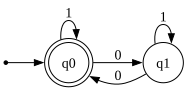

In [14]:
from visual_automata.fa.dfa import VisualDFA

dfa = VisualDFA(
    states={'q0', 'q1'},
    input_symbols={'0', '1'},
    transitions={
        'q0': {'0': 'q1', '1': 'q0'},
        'q1': {'0': 'q0', '1': 'q1'}
    },
    initial_state='q0',
    final_states={'q0'}
)
dfa.show_diagram()

# Tradução para Baixo Nível (C Mindset)
Em termos de engenharia de software, um DFA é trivial de implemetar.<br>
Ele se resume a sua m´quina de estados finitos usando uma variável de <br>
de estado e uma estrutura controle (como um ***switch-case***) dentro de um <br>
loop ***while*** que consome um buffer de memória).

# Quando a Entrada Acaba em Estado de Rejeição
Na formulação clássica, se a string de entrada termina e o <br>
autômato não pousou em um elemento do conjuto de aceitação $(F)$, <br>
a string é rejeitada. Mas computacionalmente, como tratamos o vazio <br>
ou o término?
- A **armadilha do estado morto (Trap State)**: Para que a função de <br>
transição seja matematicamente total (ou seja, precise ter uma resposta<br>
para absolutamente qualquer símbolo em qualquer estado), muitas vezes criamos <br>
um "estado lixeira". Se a máquina cai nele, ela passa o resto do *input* apenas <br>
consumindo os dados sem esperança de recuperação, antecipando a rejeição muito <br>
antes da fita acabar.



# Por que DFA sofre de "amnésia irreversível"?
Se perguntarmos ao autômato: "Quantos caracteres '0' você leu nos<br>
10 últimos passos?", ele só saberá responder se o número total couber <br>
no mapeamento estático dos seus estados.
- A **ausência de memória auxiliar**: Como ele não tem uma pilha ou uma fita <br>
de rascunho, cada transição apaga o passado imediato em favor do estado presente. <br>
Ele não consegue contar até infinito; ele só consegue categorizar classes de <br>
equivalência (por exemplo: "par vs ímpar", "resto 0, 1 ou 2 ao dividir por 3"). <br>
Se você precisar contar 1 milhão de elementos para validar uma regra, você <br>
precisará de um **DFA** com 1 milhão de estados.

# Qual é a fronteira final: O que um DFA nunca conseguirá reconhecer?
Esta é a pergunta de ouro da teoria. Por mais genial que seja o engenheiro <br>
que projete o **DFA**, existem problemas que ele jamais resolverá, não importa <br>
quantos bilhões de estados você adicione.
- O **talão de Aquiles (Linguagens Não-Regulares)**: Uma DFA é incapaz de <br>
reconhecer estruturas que exigem contagem simétrica ilimitada, como uma string <br>
da forma $a^nb^n$ (um número arbitrário de 'a's seguidos exatamente pelo mesmo <br>
números de 'b's). Por quê? <br>
Porque ele não tem onde "anotar" quantos 'a's ele viu para comparar com 'b's que <br>
estão chegando. Isso exige o próximo salto na hierarquia: o Autômato com Pilha.

# O não-determinismo (NFA) é um superpoder computacional genuíno ou apenas um atalho estético?
Se permitirmos que a máquina tenha múltiplos caminhos simultâneos para o <br>
mesmo símbolo (ou transição sem consumir símbolos, os chamados $\epsilon$-transições), <br>
entramos no território do **Autômato Finito Não-Determinístico (NFA)**.
- A **Ilusão da Simultaneidade**: O NFA parece capaz de testar todas as <br>
hipóteses do universo em paralelo. Porém, a teoria da computação prova <br>
implacavelmente que todo NFA pode ser convertido em um DFA equivalente.
- O **preço do Determinismo**: Esse milagre de conversão (conhecido como <br>
*Construções de Subconjuntos ou Powerset Construction*) cobra um preço <br>
matemático severo: o número de estados do DFA resultante pode explodir <br>
exponencialmente para $2^{Q}$. Ou seja, o não-determinismo não expande <br>
o limite do que é computável; ele apenas comprime de forma elegante a <br>
complexidade de descrição do problema.

# Como o Teorema de Myhill-Nerode extrai a "alma" matemática de uma linguagem?
Se duas equipes de engenheiros projetarem dois DFAs diferentes que <br>
aceitam exatamente a mesma linguagem, qual dele é o "verdadeiro", o <br>
mais puro e irredutível?
- A **Singularidade do Mínimo**: O **Teorema de Myhill-Nerode** responde <br>
a isso com elegância cirúgica. Ele demostra que para qualquer linguagem <br>
regular, existe um e apenas um DFA mínimo (a menos de um renomeamento de <br>
estado).
-  Ela faz isso particionando todas as strings possíveis do universo em <br>
**classes de equivalência**. Se duas strings deixam a máquina em estados <br>
indistinguíveis em relação ao futuro delas, elas pertencem à mesma classe. <br>
A minimização de um DFA não é apenas uma otimização de código; é uma limpeza <br>
ontológica para encontrar a estrutura mínima indispensável de um conceito.

# O que acontece quando o alfabeto $\sum$ explode combinatorialmente no mundo real?
Na teoria pura, o alfabeto $\sum$ é um conjunto finito e enxuto, como {$0,1$}.<br>
Mas e quando o autômato precisa processar texto em UTF-8 ou o tráfego <br>
de pacotes brutos de  uma placa de rede?
- A **Explosão de Transição**: Se o seu alfabeto possui $65.536$ símbolos (como o Unicode <br>
básico), a função de transição $\delta: Q$ x $\sum \to Q$ exige uma matriz de mapeamento <br>
massiva. Na prática de compiladores modernos (como no utilitário **Lex** ou <br>
motores de **regex** como o **RE2**), os engenheiros precisam inventar artifícios de <br>
hardware e software como intervalos de caracteres e tabelas de dispersão esparsas <br>
para comprimir o espaço de transição de um autômato sem perder a rigidez matemática <br>
do modelo.

# O Lema do Bombeamento (Pumping Lemma): O Atestado de Óbito da Regularidade
Se queremos provar cientificamente que um problema está além do alcance de um<br>
autômato finito, usamos o **Lema do Bombeamento**. Ele é a ferramenta lógica que <br>
escancara a condenação de memória finita.
- O **Princípio da Casa dos Pombos (Pigeonhole Principle)**: Se um FDA possui $n$ <br>
estados e você alimenta ele com uma string $w$ cujo comprimento é maior ou igual a <br>
$n(|w| \geq n)$, a máquina é forçada por lei matemática a visitar um mesmo estado <br>
duas vezes durante o processamento do prefixo.
- O **O Colapso do Ciclo**: Isso significa que existe um trecho repetitivo (um loop $y$)<br>
que pode se "bombear" (repetindo infinitamente ou removido) sem que o autômato perceba a <br>
alteração em seu estado final.
- A **Impossibilidade Algébrica**: É por isso que linguagens como $a^nb^n$ falham <br>
miseravelmente: se você "bombeia" apenas os $a$'s, a quantidade de $a$'s descola dos <br>
$b$'s, mas o autômato, cego pela repetição do loop, aceita a aberração provando que <br>
nenhuma máquina de estados finitos consgue sustentar essa contagem.

# O Teorema de Rabin-Scott: A Inevitabilidade Geométrica da Explosão Exponencial
Anteriormente falamos sobre a conversão de NFA para DFA. Mas quão catastrófica essa <br>
conversão pode ser no pior cenário matemático?
- O **Limite de $2^n$**: O **Teorema de Rabin-Scott** prova formalmente que se um NFA <br>
possui $n$ estados, o DFA equivalente pode exigir exatamente $2^n$ estados no pior caso. <br>
- Não se trata de uma falha de otimização humana ou de compilador mal escrito; é uma <br>
**barreira topológica**. O não-determinismo consegue comprimir o espaço de estados de <br>
forma exponencial através de sobreposição de caminhos lógicos. Quando você força a <br>
máquina a se tornar determinística, a geometria do grafo expande-se para cobrir todas <br>
as combinações possíveis de subconjuntos de estados simultâneos.

# Monoides Sintáticos: Quando os Autômatos Encontram a Álgebra Pura
Para os matemáticos mais puristas, olhar para um autômato com um conjunto de bolinhas <br>
e setas é uma visão superficial. A verdadeira essência de um DFA pode ser traduzida <br>
inteiramente em **Teoria de Semigrupos e Monoides**.
- **Funções como Operadores**: Cada símbolo do alfabeto $\sum$ pode ser visto não apenas <br>
como um gatilho, mas como uma **função de transformação** que mapeia o conjunto de estados <br>
$Q$ nele mesmo.
- A **Estrutura Algébrica**: O conjunto de todas as sequências possíveis de transições forma <br>
um monoide (um semigrupo com elemento neutro). O **Monoide Sintático** de uma linguagem regular <br>
revela a simetria oculta e a complexidade algébrica exata do problema que o autômato está <br>
resolvendo, unificando a teoria da computação com a álgebra abstrata moderna.

# Seja bem-vindo ao mundo do Autômato com Pilha (Pushdown Automaton - PDA) e à sua contraparte formal: as Linguagens Livres de Contexto (Context-Free Languages).

# Arquitetura do PDA: Conectando Memória LIFO à Máquina de Estados
O autômato finito que discutimos até agora é como um processador sem registradores <br>
de pilha: ele olha o presente e esquece o passado. O PDA adiciona uma **pilha(Stack)** <br>
estruturada em LIFO (Last In, First Out) com capacidade infinita.
- O **Salto de Poder**: A função de transição deixa de olhar apenas para o estado atual <br>
e o símbolo de entrada. Ela agora depende de um terceiro elemento: o símbolo que está no <br>
topo da pilha.
- A **Regra de Ouro da Transição**: $\delta$: $Q$ x $\sum_{\epsilon}$ x $\Gamma_{\epsilon} \to P$(Estados x $\Gamma_{\epsilon}$)
    - Onde $\sum$ é o alfabeto de entrada, e $\Gamma$ é o alfabeto da pilha.
    - Durante uma transição, a máquina pdoe ler um símbolo da entrada, **desemparelhar** <br>
(remover) o topo da pilha, e **empilhar** (adicionar) novos símbolos. Tudo em um único <br>
passo atômico.

# A Solução para o Calcanhar de Aquiles: Vencedor o $a^nb^n$
Lembra que o DFA entrava em colapso diante da string $a^nb^n$ porque ele não <br>
conseguia contar indefinidamente? o PDA resolve isso com elegância mecânica:
1. Quando a máquina lê cada caractere $\alpha$, ela executa uma ação na pilha: <br>
**empilham** um marcador (ex: o caractere X)
2. Quando ela termina os $a$'s e começa a ler os $b$, para cada $b$ consumido, <br>
ela executa a operação inversa: **desempilha** um X.
3. Se a string acabar exatamente no momento em que a pilha estiver completamente <br>
vazia, a máquina aceita a string.

- O truque: A pilha funciona como uma fita métrica elástica que cresce e encolhe <br>
na mesma proporção da entrada, permitindo que a máquina "lembre" e compare quantidades <br>
arbitrárias, desde que o acesso seja estritamente LIFO.